# 36 - System II Strict-Rejection SBC Training-Size Sweep

Experiment: retrain System II S-B posteriors on increasing matched-bank prefixes, starting at 5,000 simulations, and evaluate SBC with `reject_outside_prior=True`.

This notebook is intentionally conservative: it reuses the existing full matched training bank so the experiment isolates training-set size from simulator-bank generation, and it writes incremental JSON after each budget because strict rejection can become slow if the posterior places mass outside the prior support.

Main outputs:
- `results/36_sysII_strict_rejection_size_sweep.json`
- `results/36_sysII_strict_rejection_size_sweep.csv`
- `figures/36_sysII_strict_rejection_size_sweep.png`
- `sbi-logs/wu2003_posterior_strict_rejection_size{N}_seed{seed}.pkl`

In [1]:
import json, pathlib, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
import sys
sys.path.insert(0, str(ROOT / 'src'))
sys.path.insert(0, str(ROOT / 'scripts'))

from cstr_sbi.recycle.physics import PARAM_NAMES
from cstr_sbi.recycle.priors import PRIOR_LOW_5D, PRIOR_HIGH_5D, box_uniform_5d
from sbi_pipeline import _structure_config, _simulate_summary, train_posterior
from scipy import stats as scipy_stats

DATA = ROOT / 'data'
RESULTS = ROOT / 'results'
SBI_LOGS = ROOT / 'sbi-logs'
FIGURES = ROOT / 'figures'
for path in [RESULTS, SBI_LOGS, FIGURES]:
    path.mkdir(exist_ok=True)

FULL_BANK_PATH = DATA / 'wu2003_sbi_train_sb_n03_matched_full.npz'
SUMMARY_PATH = RESULTS / '36_sysII_strict_rejection_size_sweep.json'
CSV_PATH = RESULTS / '36_sysII_strict_rejection_size_sweep.csv'
assert FULL_BANK_PATH.exists(), FULL_BANK_PATH

STRUCTURE = 'S-B'
NOISE_PCT = 0.003
TRAIN_SIZES = [5000, 10000, 15000]
TORCH_SEED = 3
BANK_PREFIX_SEED = 20260827
ARCH = 'zuko_nsf'
HIDDEN = 60
TRANSFORMS = 3
MAX_EPOCHS = 100
STOP_AFTER_EPOCHS = 10
N_SBC_STRICT = 20
N_POST_STRICT = 50
SBC_SEED = 36260827

print(f'ROOT={ROOT}')
print(f'Full matched bank: {FULL_BANK_PATH}')
print(f'TRAIN_SIZES={TRAIN_SIZES}, TORCH_SEED={TORCH_SEED}')
print(f'Strict canary SBC: N_SBC={N_SBC_STRICT}, N_POST={N_POST_STRICT}, reject_outside_prior=True')

ROOT=/Users/simo/inso-po-RD/cstr-model-optimisation/research_project
Full matched bank: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/data/wu2003_sbi_train_sb_n03_matched_full.npz
TRAIN_SIZES=[5000, 10000, 15000], TORCH_SEED=3
Strict canary SBC: N_SBC=20, N_POST=50, reject_outside_prior=True


## 1. Prepare deterministic training-bank prefixes

Use shuffled prefixes from the existing matched full bank. This avoids paying the simulator cost again and keeps the experiment focused on training-set size.

In [2]:
full_bank = np.load(FULL_BANK_PATH)
theta_full = np.asarray(full_bank['thetas'], dtype=np.float32)
summary_full = np.asarray(full_bank['summaries'], dtype=np.float32)
assert theta_full.shape[0] >= max(TRAIN_SIZES), theta_full.shape
rng = np.random.default_rng(BANK_PREFIX_SEED)
order = rng.permutation(theta_full.shape[0])

prefix_paths = {}
for n_train in TRAIN_SIZES:
    out = DATA / f'wu2003_sbi_train_sb_n03_matched_prefix_{n_train}.npz'
    idx = order[:n_train]
    np.savez(out, thetas=theta_full[idx], summaries=summary_full[idx])
    prefix_paths[n_train] = out
    print(f'wrote {out.name}: {n_train} samples, summaries={summary_full.shape[1]}')

wrote wu2003_sbi_train_sb_n03_matched_prefix_5000.npz: 5000 samples, summaries=66
wrote wu2003_sbi_train_sb_n03_matched_prefix_10000.npz: 10000 samples, summaries=66
wrote wu2003_sbi_train_sb_n03_matched_prefix_15000.npz: 15000 samples, summaries=66


## 2. Strict-rejection SBC helper

This is the same matched-protocol SBC loop used by `sbi_pipeline.run_sbc`, except posterior sampling explicitly uses `reject_outside_prior=True`. Timing is recorded per SBC draw so rejection slowdowns are visible.

In [3]:
def run_sbc_strict_rejection(posterior, n_sbc=N_SBC_STRICT, n_post=N_POST_STRICT, seed=SBC_SEED):
    ctrl, y0 = _structure_config(STRUCTURE)
    prior = box_uniform_5d()
    rng = np.random.default_rng(seed)
    ranks = {name: [] for name in PARAM_NAMES}
    draw_seconds = []
    n_valid = 0
    t0 = time.time()

    for i in range(n_sbc):
        th = prior.sample((1,)).numpy()[0]
        s = _simulate_summary(th, ctrl, y0, STRUCTURE, NOISE_PCT, rng, scenario_specific_warm_start=True)
        if s is None:
            continue
        n_valid += 1
        t_draw = time.time()
        with torch.no_grad():
            samp = posterior.sample(
                (n_post,),
                x=torch.tensor(s, dtype=torch.float32),
                show_progress_bars=False,
                reject_outside_prior=True,
            ).detach().cpu().numpy()
        draw_seconds.append(time.time() - t_draw)
        for k, name in enumerate(PARAM_NAMES):
            ranks[name].append(int(np.sum(samp[:, k] < th[k])))
        if (i + 1) % 10 == 0:
            print(f'[strict-sbc] {i+1}/{n_sbc} ({time.time()-t0:.0f}s, valid={n_valid}, last_sample_s={draw_seconds[-1]:.2f})')

    results = {
        'n_sbc': n_sbc,
        'n_post': n_post,
        'n_valid': n_valid,
        'reject_outside_prior': True,
        'sample_seconds_mean': float(np.mean(draw_seconds)) if draw_seconds else None,
        'sample_seconds_p95': float(np.percentile(draw_seconds, 95)) if draw_seconds else None,
        'sample_seconds_max': float(np.max(draw_seconds)) if draw_seconds else None,
    }
    for name in PARAM_NAMES:
        r = np.asarray(ranks[name], dtype=float)
        ks = scipy_stats.ks_1samp(r / n_post, scipy_stats.uniform.cdf) if len(r) else None
        results[name] = {
            'ranks': r.astype(int).tolist(),
            'ks_pvalue': float(ks.pvalue) if ks is not None else None,
            'mean_rank_frac': float(r.mean() / n_post) if len(r) else None,
        }
    results['min_ks_pvalue'] = min(results[name]['ks_pvalue'] for name in PARAM_NAMES)
    print(f'[strict-sbc] completed in {time.time()-t0:.0f}s; min KS p={results["min_ks_pvalue"]:.3e}')
    return results

def flatten_sbc_row(row):
    rec = {
        'n_train': row['n_train'],
        'torch_seed': row['torch_seed'],
        'train_wall_s': row['train_wall_s'],
        'strict_sbc_wall_s': row['strict_sbc_wall_s'],
        'min_ks_pvalue': row['sbc']['min_ks_pvalue'],
        'sample_seconds_mean': row['sbc']['sample_seconds_mean'],
        'sample_seconds_p95': row['sbc']['sample_seconds_p95'],
        'sample_seconds_max': row['sbc']['sample_seconds_max'],
    }
    for name in PARAM_NAMES:
        rec[f'{name}_ks_pvalue'] = row['sbc'][name]['ks_pvalue']
        rec[f'{name}_mean_rank_frac'] = row['sbc'][name]['mean_rank_frac']
    return rec

## 3. Train size sweep and strict SBC

Run one seed across increasing training sizes. If strict rejection becomes very slow, the last printed `last_sample_s` and the incremental JSON indicate where it stalled.

In [4]:
all_results = []
t_all = time.time()
for n_train in TRAIN_SIZES:
    variant = f'strict_rejection_size{n_train}_seed{TORCH_SEED}'
    posterior_path = SBI_LOGS / f'wu2003_posterior_{variant}.pkl'
    print(f'\n=== {variant} ===')

    if posterior_path.exists():
        with open(posterior_path, 'rb') as f:
            payload = pickle.load(f)
        posterior = payload['posterior']
        train_wall_s = float(payload.get('train_wall_s', 0.0))
        print(f'loaded existing posterior: {posterior_path}')
    else:
        t_train = time.time()
        posterior = train_posterior(
            bank_path=prefix_paths[n_train],
            arch=ARCH,
            hidden_features=HIDDEN,
            num_transforms=TRANSFORMS,
            max_num_epochs=MAX_EPOCHS,
            stop_after_epochs=STOP_AFTER_EPOCHS,
            torch_seed=TORCH_SEED,
        )
        train_wall_s = time.time() - t_train
        with open(posterior_path, 'wb') as f:
            pickle.dump({
                'posterior': posterior,
                'variant': variant,
                'n_train': n_train,
                'torch_seed': TORCH_SEED,
                'arch': ARCH,
                'hidden_features': HIDDEN,
                'num_transforms': TRANSFORMS,
                'bank_path': str(prefix_paths[n_train]),
                'scenario_specific_warm_start': True,
                'train_wall_s': train_wall_s,
            }, f)
        print(f'saved trained posterior before strict SBC: {posterior_path}')

    t_sbc = time.time()
    sbc = run_sbc_strict_rejection(posterior, n_sbc=N_SBC_STRICT, n_post=N_POST_STRICT, seed=SBC_SEED + n_train)
    strict_sbc_wall_s = time.time() - t_sbc

    payload = {
        'posterior': posterior,
        'variant': variant,
        'n_train': n_train,
        'torch_seed': TORCH_SEED,
        'arch': ARCH,
        'hidden_features': HIDDEN,
        'num_transforms': TRANSFORMS,
        'bank_path': str(prefix_paths[n_train]),
        'scenario_specific_warm_start': True,
        'reject_outside_prior': True,
        'train_wall_s': train_wall_s,
        'strict_sbc_wall_s': strict_sbc_wall_s,
        'sbc': sbc,
    }
    with open(posterior_path, 'wb') as f:
        pickle.dump(payload, f)

    row = {
        'variant': variant,
        'n_train': n_train,
        'torch_seed': TORCH_SEED,
        'train_wall_s': train_wall_s,
        'strict_sbc_wall_s': strict_sbc_wall_s,
        'posterior_path': str(posterior_path),
        'sbc': sbc,
    }
    all_results.append(row)

    summary = {
        'status': 'in_progress',
        'structure': STRUCTURE,
        'noise_pct': NOISE_PCT,
        'train_sizes': TRAIN_SIZES,
        'completed_train_sizes': [r['n_train'] for r in all_results],
        'torch_seed': TORCH_SEED,
        'arch': ARCH,
        'hidden_features': HIDDEN,
        'num_transforms': TRANSFORMS,
        'max_epochs': MAX_EPOCHS,
        'stop_after_epochs': STOP_AFTER_EPOCHS,
        'n_sbc_strict': N_SBC_STRICT,
        'n_post_strict': N_POST_STRICT,
        'reject_outside_prior': True,
        'results': all_results,
        'elapsed_wall_s': time.time() - t_all,
    }
    with open(SUMMARY_PATH, 'w') as f:
        json.dump(summary, f, indent=2)
    pd.DataFrame([flatten_sbc_row(r) for r in all_results]).to_csv(CSV_PATH, index=False)
    print(f'wrote incremental summary: {SUMMARY_PATH}')

final_summary = {**summary, 'status': 'complete'}
with open(SUMMARY_PATH, 'w') as f:
    json.dump(final_summary, f, indent=2)
sweep_df = pd.DataFrame([flatten_sbc_row(r) for r in all_results])
sweep_df.to_csv(CSV_PATH, index=False)
display(sweep_df)
print(f'total wall time: {(time.time() - t_all)/3600:.2f} h')


=== strict_rejection_size5000_seed3 ===


loaded existing posterior: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/sbi-logs/wu2003_posterior_strict_rejection_size5000_seed3.pkl


[strict-sbc] 10/20 (10s, valid=10, last_sample_s=0.02)


[strict-sbc] 20/20 (66s, valid=20, last_sample_s=0.02)
[strict-sbc] completed in 66s; min KS p=2.975e-01
wrote incremental summary: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/36_sysII_strict_rejection_size_sweep.json

=== strict_rejection_size10000_seed3 ===
loaded existing posterior: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/sbi-logs/wu2003_posterior_strict_rejection_size10000_seed3.pkl


[strict-sbc] 10/20 (54s, valid=10, last_sample_s=0.02)


[strict-sbc] 20/20 (114s, valid=20, last_sample_s=0.01)
[strict-sbc] completed in 114s; min KS p=1.926e-02
wrote incremental summary: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/36_sysII_strict_rejection_size_sweep.json

=== strict_rejection_size15000_seed3 ===
[train] 15000 samples, 66-D summaries, arch=zuko_nsf hidden=60 transforms=3


... (76 outputs left out)

[strict-sbc] 10/20 (10s, valid=10, last_sample_s=0.02)


[strict-sbc] 20/20 (20s, valid=20, last_sample_s=0.01)
[strict-sbc] completed in 20s; min KS p=7.039e-02
wrote incremental summary: /Users/simo/inso-po-RD/cstr-model-optimisation/research_project/results/36_sysII_strict_rejection_size_sweep.json


,n_train,torch_seed,train_wall_s,strict_sbc_wall_s,min_ks_pvalue,sample_seconds_mean,sample_seconds_p95,sample_seconds_max,alpha_ks_pvalue,alpha_mean_rank_frac,beta_r_ks_pvalue,beta_r_mean_rank_frac,eta_col_ks_pvalue,eta_col_mean_rank_frac,xi_reb_ks_pvalue,xi_reb_mean_rank_frac,z_A0_eff_ks_pvalue,z_A0_eff_mean_rank_frac
0,5000,3,0.000000,71.002433,0.297519,0.036177,0.041306,0.492421,0.628522,0.482,0.553291,0.491,0.352720,0.454,0.481276,0.567,0.297519,0.509
1,10000,3,0.000000,118.058708,0.019261,0.012019,0.021462,0.021772,0.019261,0.356,0.025418,0.359,0.205962,0.611,0.628522,0.488,0.043067,0.380
2,15000,3,43.740663,25.049403,0.070389,0.013569,0.023247,0.029149,0.070389,0.347,0.845577,0.472,0.169104,0.400,0.205962,0.563,0.297519,0.403


total wall time: 0.07 h


## 4. Plot strict-rejection size trend

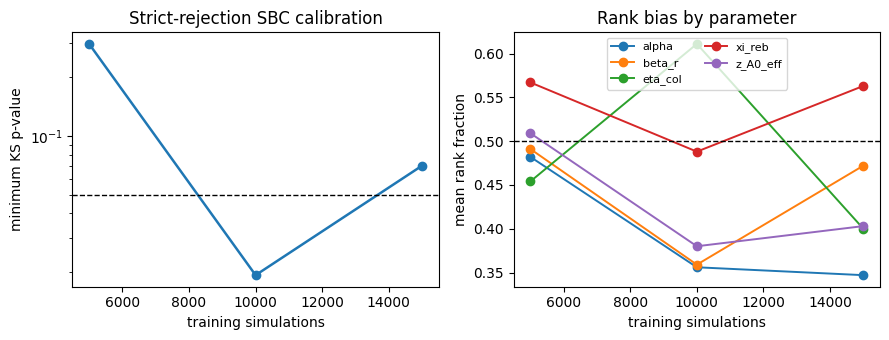

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(9.0, 3.5))
axes[0].plot(sweep_df['n_train'], sweep_df['min_ks_pvalue'], marker='o', lw=1.8)
axes[0].axhline(0.05, color='k', ls='--', lw=1.0)
axes[0].set_yscale('log')
axes[0].set_xlabel('training simulations')
axes[0].set_ylabel('minimum KS p-value')
axes[0].set_title('Strict-rejection SBC calibration')

for name in PARAM_NAMES:
    axes[1].plot(sweep_df['n_train'], sweep_df[f'{name}_mean_rank_frac'], marker='o', lw=1.4, label=name)
axes[1].axhline(0.5, color='k', ls='--', lw=1.0)
axes[1].set_xlabel('training simulations')
axes[1].set_ylabel('mean rank fraction')
axes[1].set_title('Rank bias by parameter')
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / '36_sysII_strict_rejection_size_sweep.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Decision rule

Interpretation rule for this exploratory sweep:

- If `reject_outside_prior=True` materially improves min-KS without large sampling times, the previous failure was partly a support-handling artifact; follow up with a larger strict-SBC confirmation.
- If strict rejection is slow or still fails, the issue is likely upstream of rejection: summary heavy tails/scaling, prior/domain tension, architecture/preprocessing, or the matched simulator protocol itself.
- Do not promote any posterior from this notebook directly; it is a diagnostic size sweep, not a production confirmation.